In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df=pd.read_excel(r"/Users/pradeepv/Downloads/beer-serving1.xlsx")
df

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
188,Venezuela,76,100,3,7.7,South America
189,Vietnam,111,2,1,2.0,Asia
190,Yemen,6,0,0,0.1,Asia
191,Zambia,32,19,4,2.5,Africa


In [45]:
#Checking for null values
df.isnull().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

Text(0.5, 1.0, 'total_litres_of_pure_alcohol')

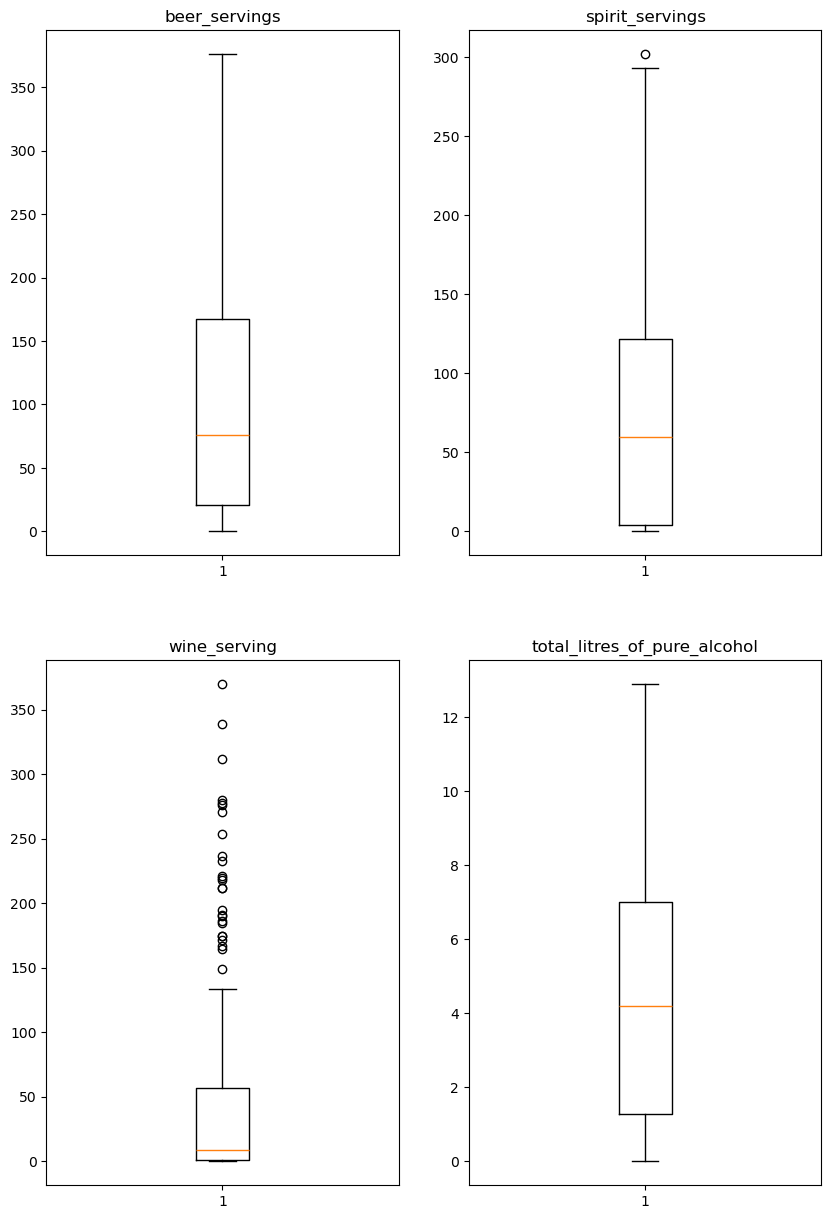

In [46]:
#Ploting box plot for checking outliers
plt.figure(figsize=(10,15))
plt.subplot(2,2,1)
plt.boxplot(df["beer_servings"])
plt.title("beer_servings")
plt.subplot(2,2,2)
plt.boxplot(df['spirit_servings'])
plt.title('spirit_servings')
plt.subplot(2,2,3)
plt.boxplot(df['wine_servings'])
plt.title("wine_serving")
plt.subplot(2,2,4)
plt.boxplot(df['total_litres_of_pure_alcohol'])
plt.title('total_litres_of_pure_alcohol')

In [22]:
#using IQR METHOD TO REMOVE OUTLIER
Q1=np.percentile(df['spirit_servings'],25,method='midpoint')
Q2=np.percentile(df['spirit_servings'],50,method='midpoint')
Q3=np.percentile(df['spirit_servings'],75,method='midpoint')
print(Q1)
print(Q2)
print(Q3)

5.0
60.0
128.0


In [23]:
IQR=Q3-Q1
print(IQR)

123.0


In [25]:
upper_limit=Q3+1.5*(IQR)
lower_limit=Q1-1.5*(IQR)
print(upper_limit)
print(lower_limit)

312.5
-179.5


In [47]:
#Detecting outliers
outlier=[]
for i in df['spirit_servings']:
    if ((i>upper_limit) or (i<lower_limit)):
        outlier.append(i)
print(outlier)

[]


In [48]:
#Outliers shows true and remaining shows false
df1=(df['spirit_servings']>upper_limit) | (df['spirit_servings']<lower_limit)
df1

0      False
1      False
2      False
3      False
4      False
       ...  
183    False
184    False
185    False
186    False
187    False
Name: spirit_servings, Length: 188, dtype: bool

In [49]:
#locating the outlier indexs
x=df.loc[df1]
x

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent


In [50]:
#Droping the outlier rows
df.drop(x.index,inplace=True)

In [35]:
df.shape

(188, 6)

In [51]:
#After removing the outlier reset the index shape 
df=df.reset_index(drop=True)

In [52]:
df

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
183,Venezuela,76,100,3,7.7,South America
184,Vietnam,111,2,1,2.0,Asia
185,Yemen,6,0,0,0.1,Asia
186,Zambia,32,19,4,2.5,Africa


In [53]:
df.isnull().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

In [40]:
#After cleaning checking for outlier
outlier=[]
for i in df['spirit_servings']:
    if ((i>upper_limit) or (i<lower_limit)):
        outlier.append(i)
print(outlier)

[]


In [55]:
df.to_excel(r"/Users/pradeepv/Downloads/beer-null-outliers.xlsx",index=False)